In [4]:
import torch
import torch.nn as nn
from torch.optim import AdamW
from torch.optim.lr_scheduler import LambdaLR
from torch.utils.data import DataLoader, random_split
import torchvision.datasets as datasets
from torchvision.transforms import v2
import matplotlib.pyplot as plt
from matplotlib.animation import FFMpegWriter
from matplotlib.ticker import ScalarFormatter
import math, humanize

class CLSViz:
  def __init__(self, base_img, num_layers, num_heads, patch_size):
    img = base_img.detach().clone()
    if img.shape[0] in (1, 3):
      img = img.permute(1, 2, 0)
    height, width = img.shape[0:2]

    self.num_heads = num_heads
    self.num_patches = (height // patch_size, width // patch_size)
    self.scaley, self.scalex = height // self.num_patches[0], width // self.num_patches[1]

    self.fig, self.axes = plt.subplots(
      num_heads, num_layers, squeeze=False,
      figsize=(3 * num_layers, 3 * num_heads), constrained_layout=True
    )
    self.heatmap_artists = [[None] * num_layers for _ in range(num_heads)]

    for head in range(num_heads):
      for layer in range(num_layers):
        ax = self.axes[head, layer]
        ax.axis("off")
        ax.imshow(img)
        self.heatmap_artists[head][layer] = ax.imshow(
          torch.zeros(height, width).numpy(),
          cmap="magma", alpha=0.45, vmin=0, vmax=0.1
        )

  def update(self, layer_scores, epoch):
    # layer_scores.shape = [layer, batch, attention head, num_patches]
    self.fig.suptitle(f"Class-token attention per layer, Epoch {epoch + 1}")

    for head in range(len(self.axes)):
      for layer in range(len(self.axes[head])):
        heatmap = layer_scores[layer, 0, head].detach().cpu()
        heatmap = heatmap.reshape(*self.num_patches)
        heatmap = heatmap.repeat_interleave(self.scaley, dim=0)
        heatmap = heatmap.repeat_interleave(self.scalex, dim=1)
        self.heatmap_artists[head][layer].set_data(heatmap.numpy())

def plot_loss_curves(train_losses, val_losses, output_path):
  train_losses = torch.tensor(train_losses)
  val_losses = torch.tensor(val_losses)

  fig, ax = plt.subplots()
  formatter = ScalarFormatter()
  formatter.set_scientific(False)

  ax.set_title("Loss Curves")
  ax.set_xlabel("Epochs")
  ax.set_ylabel("Loss")
  ax.set_yscale("log")
  ax.yaxis.set_major_formatter(formatter)

  ax.plot(train_losses, "b-", label="Training loss")
  ax.plot(val_losses, "r-", label="Validation loss")

  stats = f"min: {train_losses.min().item():.3}, max: {train_losses.max().item():.3}, " + \
          f"mean: {train_losses.mean().item():.3}, std: {train_losses.std().item():.3}, "
  ax.text(0.5, -0.18, f"Train loss | {stats}",
          transform=ax.transAxes, ha="center", va="top", fontsize=10)

  stats = f"min: {val_losses.min().item():.3}, max: {val_losses.max().item():.3}, " + \
          f"mean: {val_losses.mean().item():.3}, std: {val_losses.std().item():.3}, "
  ax.text(0.5, -0.36, f"Validation loss | {stats}",
          transform=ax.transAxes, ha="center", va="top", fontsize=10)

  fig.tight_layout()
  fig.savefig(output_path, bbox_inches="tight")
  plt.legend()
  plt.show()

In [5]:
def custom_lr_scheduler(step, warmup, total):
  if step < warmup:
    return float(step) / float(max(1, warmup))

  # Cosine decay phase
  progress = float(step - warmup) / float(max(1, total - warmup))
  progress = min(1.0, max(0.0, progress))
  return 0.5 * (1.0 + math.cos(math.pi * progress))

def patchify_img(img_batch, B, C, P, G):
  # Convert image into a sequence of patches
  patches = img_batch.unfold(2, P, P).unfold(3, P, P)
  patches = patches.contiguous().view(B, C, G * G, P, P)
  patches = patches.permute(0, 2, 3, 4, 1)
  patches = patches.flatten(start_dim=2, end_dim=4)
  return patches

def init_weights(module):
  if isinstance(module, nn.Linear):
    nn.init.kaiming_uniform_(module.weight)
    if module.bias is not None:
      nn.init.zeros_(module.bias)

class ViTLayer(nn.Module):
  def __init__(self, embed_dim, num_heads, dropout):
    super().__init__()
    self.norm1 = nn.LayerNorm(embed_dim)
    self.msa = nn.MultiheadAttention(embed_dim, num_heads,
                                     dropout=dropout, batch_first=True)
    self.norm2 = nn.LayerNorm(embed_dim)
    self.ffn = nn.Sequential(
      nn.Linear(embed_dim, embed_dim * 4),
      nn.GELU(),
      nn.Dropout(dropout),
      nn.Linear(embed_dim * 4, embed_dim),
      nn.Dropout(dropout)
    )

  def forward(self, prev_output):
    n = self.norm1(prev_output)
    z1, attn_scores = self.msa(n, n, n, average_attn_weights=False)
    z1 = prev_output + z1
    output = self.ffn(self.norm2(z1)) + z1
    return output, attn_scores

class ViT(nn.Module):
  def __init__(self, patch_size, grid_size, embed_dim,
               dropout, layers, num_heads, num_classes):
    super().__init__()
    size = 3 * patch_size * patch_size
    elements = grid_size * grid_size + 1

    self.embed_filters = nn.Linear(size, embed_dim, bias=False)
    self.class_token = nn.Parameter(torch.zeros(embed_dim))
    self.pos_embed = nn.Parameter(torch.rand(elements, embed_dim))
    nn.init.normal_(self.class_token, std=0.02)
    nn.init.normal_(self.pos_embed, std=0.02)

    self.layers = nn.ModuleList([
      ViTLayer(embed_dim, num_heads, dropout) for _ in range(layers)
    ])
    self.class_norm = nn.LayerNorm(embed_dim)
    self.class_proj = nn.Linear(embed_dim, num_classes)

  # P = patch size, N = patch count, C = channel count
  # B = batch size, O = number of output classes
  # Input shape: (B, N, P * P * C), output shape: (B, O)
  def forward(self, x, store_cls_scores):
    embeddings = self.embed_filters(x)
    tok = self.class_token.unsqueeze(0).unsqueeze(0)
    tok = tok.expand(x.shape[0], -1, -1)
    tokens = torch.cat((tok, embeddings), dim=1)
    state = tokens + self.pos_embed

    cls_scores = []
    for layer in self.layers:
      state, attn_scores = layer(state)
      if store_cls_scores:
        # Get the attention scores of all patches with respect to the [cls] token
        row = attn_scores[:, :, 0, 1:]
        cls_scores.append(row)

    class_token = self.class_norm(state[:, 0])
    output = self.class_proj(class_token)
    scores = torch.stack(cls_scores) if store_cls_scores else None
    return output, scores

class Harness:
  def __init__(self, hyperparams, img_size, device):
    self.h = hyperparams
    self.patches_per_side = img_size // self.h["patch_size"]
    self.device = device

    self.model = ViT(
      self.h["patch_size"],
      self.patches_per_side,
      self.h["embedding_dim"],
      self.h["dropout"],
      self.h["layers"],
      self.h["num_heads"],
      self.h["num_classes"],
    ).apply(init_weights).to(self.device)
    self.num_params = sum(p.numel() for p in self.model.parameters() if p.requires_grad)

    self.optimizer = AdamW(self.model.parameters(),
                           lr=self.h["learning_rate"],
                           betas=self.h["betas"],
                           weight_decay=self.h["weight_decay"])
    self.criterion = nn.CrossEntropyLoss()

  def run_model(self, images, labels, scheduler=None):
    # Images shape: (B, C, H, W), Patches shape: (B, N, P, P, C)
    images, labels = images.to(self.device), labels.to(self.device)
    patches = patchify_img(
      images, images.shape[0],
      images.shape[1], self.h["patch_size"],
      self.patches_per_side
    )

    prediction, scores = self.model(patches, scheduler is None)
    loss = self.criterion(prediction, labels)
    if scheduler is not None:
      loss.backward()
      self.optimizer.step()
      self.optimizer.zero_grad(set_to_none=False)
      scheduler.step()

    return scores, loss.item()

Training a 322 k model using cuda
Validation loss for epoch 1 = 2.281
Validation loss for epoch 2 = 2.204
Validation loss for epoch 3 = 1.987
Validation loss for epoch 4 = 1.824
Validation loss for epoch 5 = 1.758
Validation loss for epoch 6 = 1.721
Validation loss for epoch 7 = 1.776
Validation loss for epoch 8 = 1.656
Validation loss for epoch 9 = 1.771
Validation loss for epoch 10 = 1.602
Validation loss for epoch 11 = 1.623
Validation loss for epoch 12 = 1.588
Validation loss for epoch 13 = 1.56
Validation loss for epoch 14 = 1.541
Validation loss for epoch 15 = 1.524
Validation loss for epoch 16 = 1.553
Validation loss for epoch 17 = 1.532
Validation loss for epoch 18 = 1.488
Validation loss for epoch 19 = 1.492
Validation loss for epoch 20 = 1.477
Validation loss for epoch 21 = 1.467
Validation loss for epoch 22 = 1.47
Validation loss for epoch 23 = 1.443
Validation loss for epoch 24 = 1.468
Validation loss for epoch 25 = 1.448
Validation loss for epoch 26 = 1.455
Validation loss

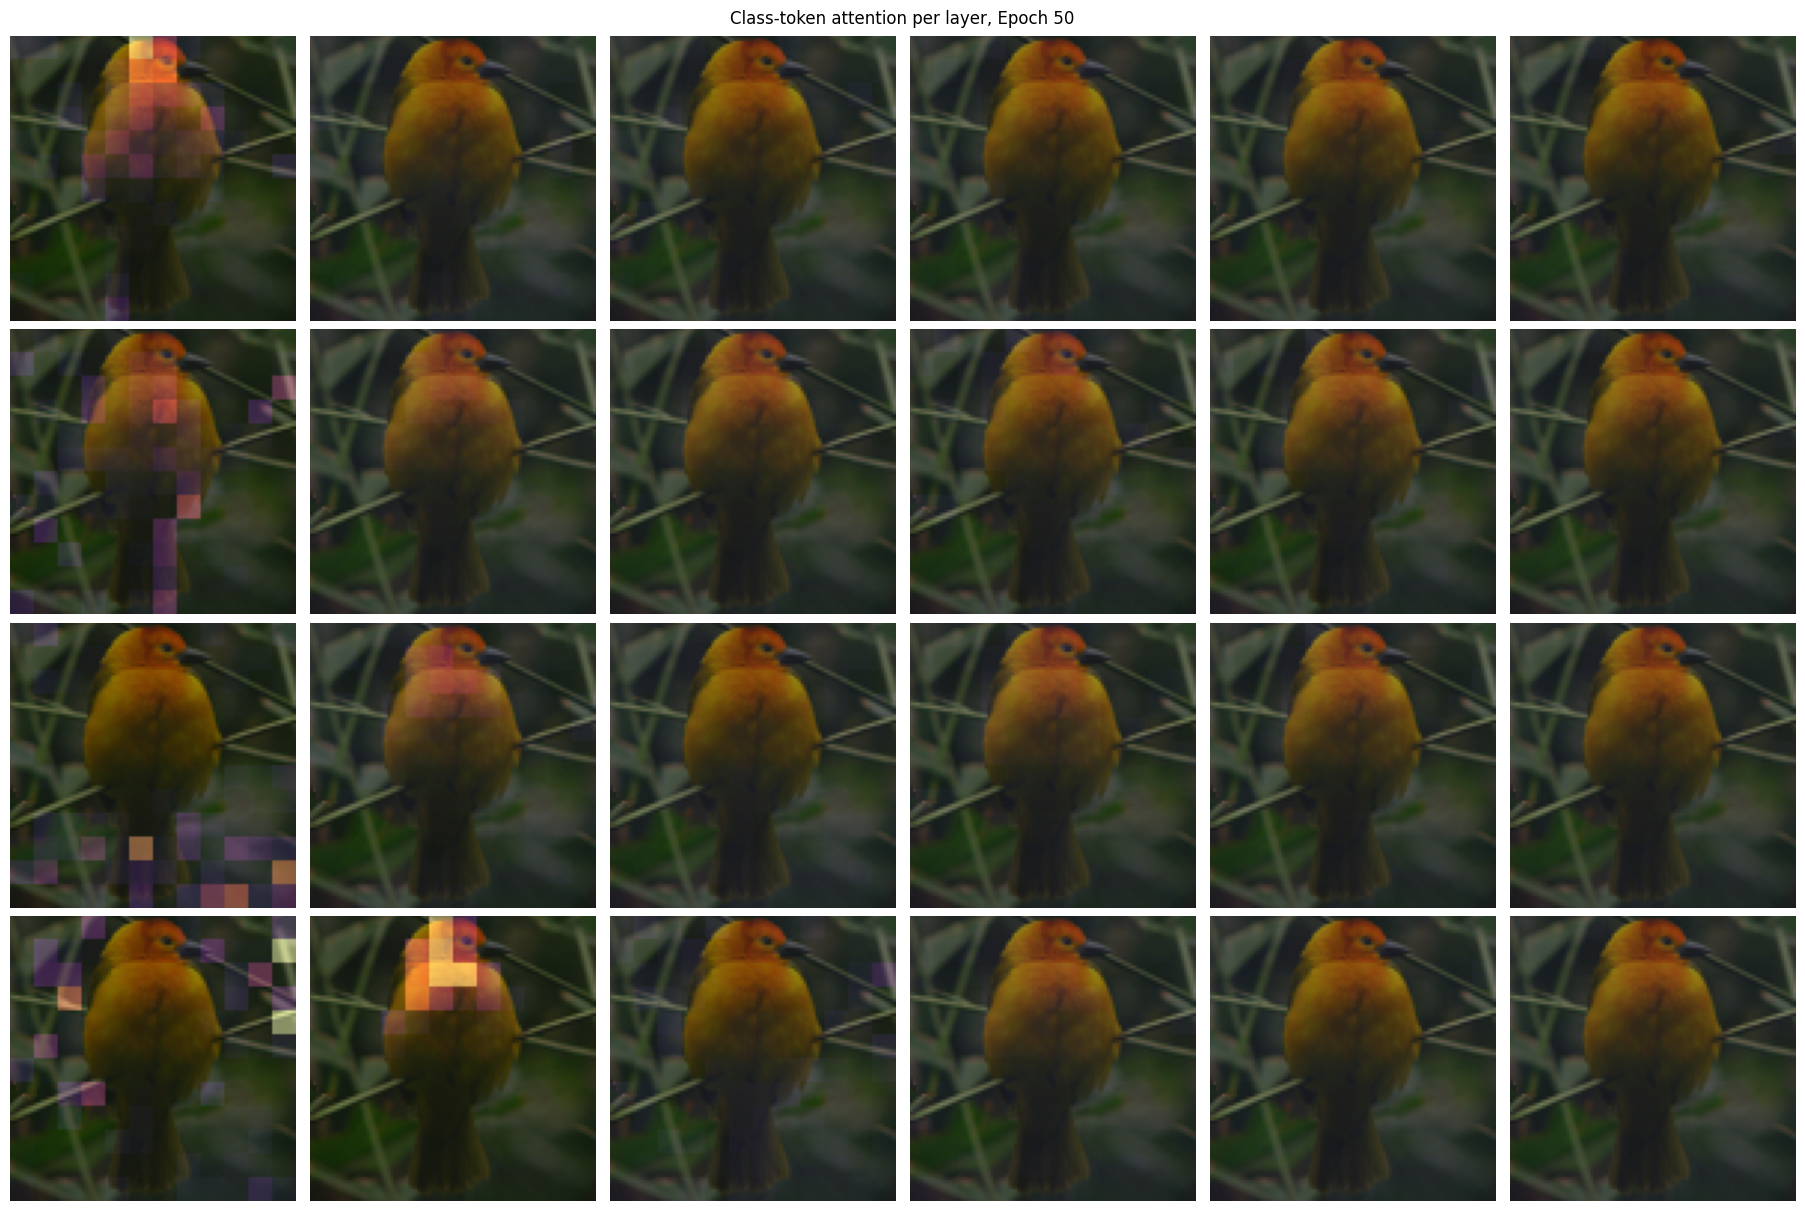

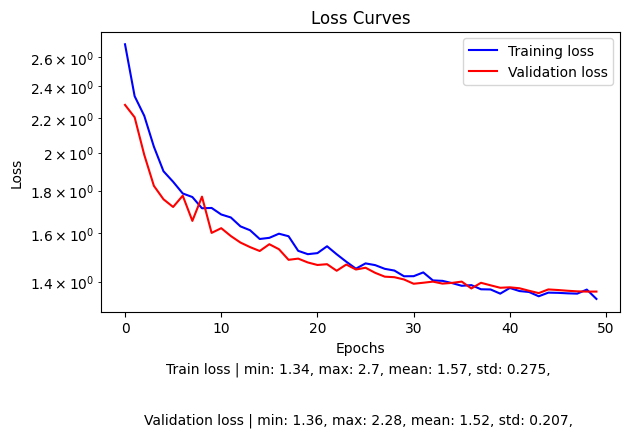

In [6]:
torch.manual_seed(67)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

hp = {
  "epochs": 50,
  "warmup_epochs": 3,
  "batch_size": 128,
  "learning_rate": 3e-4,
  "betas": [0.9, 0.999],
  "embedding_dim": 64,
  "patch_size": 8,
  "num_heads": 4,
  "layers": 6,
  "num_classes": 10,
  "dropout": 0.1,
  "weight_decay": 0.01
}

val_pipeline = v2.Compose([ v2.RGB(), v2.ToImage(), v2.ToDtype(torch.float32, scale=True) ])
train_pipeline = v2.Compose([
  v2.RGB(), v2.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
  v2.RandomResizedCrop(96, scale=(0.7, 1.0)), v2.RandomHorizontalFlip(),
  v2.ToImage(), v2.ToDtype(torch.float32, scale=True),
])

train_set = datasets.STL10(root=".cache/stl10", split="train", download=True, transform=train_pipeline)
val_set = datasets.STL10(root=".cache/stl10", split="test", download=True, transform=val_pipeline)
train_loader = DataLoader(train_set, shuffle=True, batch_size=hp["batch_size"])
val_loader = DataLoader(val_set, batch_size=hp["batch_size"])

rand_idx = torch.randint(0, len(train_set), size=(1,))
viz_img, viz_label = val_set[rand_idx]
viz_img, img_size = viz_img.unsqueeze(0), viz_img.shape[-1]
viz_label = torch.full((1,), viz_label)

viz = CLSViz(viz_img[0], hp["layers"], hp["num_heads"], hp["patch_size"])
writer = FFMpegWriter(fps=1)

harness = Harness(hp, img_size, device)
total_steps = hp["epochs"] * len(train_loader)
warmup_steps = hp["warmup_epochs"] * len(train_loader)
scheduler = LambdaLR(harness.optimizer,
                     lambda step: custom_lr_scheduler(step, warmup_steps, total_steps))

print(f"Training a {humanize.metric(harness.num_params)} model using {device}")
train_losses, val_losses = [], []

with writer.saving(viz.fig, "cls_attention.mp4", dpi=120):
  for epoch in range(hp["epochs"]):
    # Training loop
    harness.model.train()
    with torch.enable_grad():
      batch_losses = []
      for images, labels in train_loader:
        _, loss = harness.run_model(images, labels, scheduler=scheduler)
        batch_losses.append(loss)
      avg_loss = sum(batch_losses) / len(batch_losses)
      train_losses.append(avg_loss)

    # Validation loop
    harness.model.eval()
    with torch.no_grad():
      # Calculate the validation loss
      batch_losses = []
      for images, labels in val_loader:
        _, loss = harness.run_model(images, labels)
        batch_losses.append(loss)
      avg_loss = sum(batch_losses) / len(batch_losses)
      val_losses.append(avg_loss)
      print(f"Validation loss for epoch {epoch + 1} = {avg_loss:.4}")

      # Visualize the test image overlayed with [cls] attention scores
      layer_cls_scores, _ = harness.run_model(viz_img, viz_label)
      viz.update(layer_cls_scores, epoch)
      writer.grab_frame()

plot_loss_curves(train_losses, val_losses, "loss_curves.png")